# Volatility Forecasting with GARCH

**Goal.** Volatility drives option prices, VaR, position sizing and risk budgets, and unlike
returns it is predictable: calm follows calm, storms follow storms. This project estimates
GARCH models by maximum likelihood and checks, out of sample, whether they forecast
better than the simple rules many desks still use.

| Model | Variance equation |
|---|---|
| Rolling historical (20d, 60d) | average of recent squared returns |
| EWMA (RiskMetrics) | $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)r_{t-1}^2$, λ = 0.94 |
| GARCH(1,1) | $\sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2$ |
| GJR-GARCH + Student-t | adds $\gamma\,\mathbb{1}\{\varepsilon_{t-1}<0\}\,\varepsilon_{t-1}^2$ (leverage effect) and fat tails |

**Data.** Ten years of daily returns of an equity index simulated from a GJR-GARCH-t
process. Because the true volatility is known, we can measure forecast errors exactly,
which is impossible with market data.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("garch.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/16-garch-volatility-forecasting")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t as student_t
from garch import fit, variance_path, forecast_variance, news_impact, simulate, ewma_variance, qlike

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
TRUE = dict(omega=2e-6, alpha=0.02, gamma=0.12, beta=0.90)
n = 2520
r = simulate(n, **TRUE, nu=6, mu=0.0003, seed=21)
true_var = variance_path(r - 0.0003, **TRUE, init=TRUE["omega"] / (1 - 0.02 - 0.06 - 0.90))[:-1]
dates = pd.bdate_range("2016-01-04", periods=n)
print(f"Annualised vol {r.std() * np.sqrt(252):.1%}, excess kurtosis {pd.Series(r).kurt():.1f}")

Annualised vol 14.2%, excess kurtosis 2.8


## 1. Volatility clustering

Returns themselves are almost uncorrelated, but their **squares** are strongly
autocorrelated: that is the signature GARCH is built to capture.

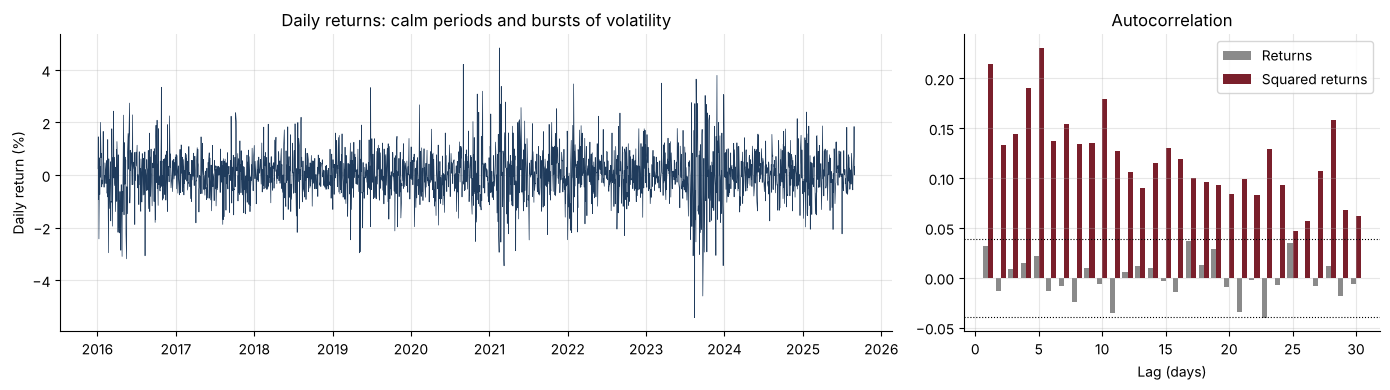

In [2]:
def acf(x, lags=30):
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, lags + 1)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(dates, r * 100, color=NAVY, lw=0.5)
axes[0].set(ylabel="Daily return (%)", title="Daily returns: calm periods and bursts of volatility")
lags = np.arange(1, 31)
axes[1].bar(lags - 0.2, acf(r), width=0.4, color=GREY, label="Returns")
axes[1].bar(lags + 0.2, acf(r**2), width=0.4, color=BORDEAUX, label="Squared returns")
axes[1].axhline(1.96 / np.sqrt(n), color="black", ls=":", lw=0.8); axes[1].axhline(-1.96 / np.sqrt(n), color="black", ls=":", lw=0.8)
axes[1].set(xlabel="Lag (days)", title="Autocorrelation"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/clustering.png", dpi=150); plt.show()

## 2. Maximum likelihood estimation

Parameters are estimated on the first 7 years (in-sample); the last 3 years are kept for
out-of-sample testing. The log-likelihood is maximised under the stationarity constraint
$\alpha + \gamma/2 + \beta < 1$, on returns in percent for numerical stability.

In [3]:
split = int(n * 0.7)
fits = {"GARCH (normal)": fit(r[:split]), "GJR (normal)": fit(r[:split], asym=True),
        "GJR (Student-t)": fit(r[:split], asym=True, student=True)}
tab = pd.DataFrame({k: {"alpha": f.alpha, "gamma": f.gamma, "beta": f.beta, "nu": f.nu, "persistence": f.persistence,
                        "half-life (days)": f.half_life, "long-run vol (ann.)": f.long_run_vol * np.sqrt(252),
                        "log-likelihood": f.loglik, "AIC": f.aic} for k, f in fits.items()})
tab["True process"] = [TRUE["alpha"], TRUE["gamma"], TRUE["beta"], 6, 0.98, np.log(0.5) / np.log(0.98),
                       np.sqrt(TRUE["omega"] / 0.02 * 252), np.nan, np.nan]
tab.round(4)

,GARCH (normal),GJR (normal),GJR (Student-t),True process
alpha,0.0581,0.0023,0.0086,0.0200
gamma,0.0000,0.0957,0.0935,0.1200
beta,0.9121,0.9211,0.9135,0.9000
nu,NaN,NaN,6.5582,6.0000
persistence,0.9702,0.9712,0.9688,0.9800
half-life (days),22.9157,23.7454,21.9010,34.3096
long-run vol (ann.),0.1366,0.1385,0.1395,0.1587
log-likelihood,5955.0039,5971.2248,6008.0608,NaN
AIC,-11902.0077,-11932.4496,-12004.1216,NaN


The GJR-t model has the lowest AIC and lands close to the true parameters, within the
sampling error of seven years of data. It captures the **leverage effect** ($\gamma \gg \alpha$):
a fall in the market raises volatility far more than a rise of the same size.

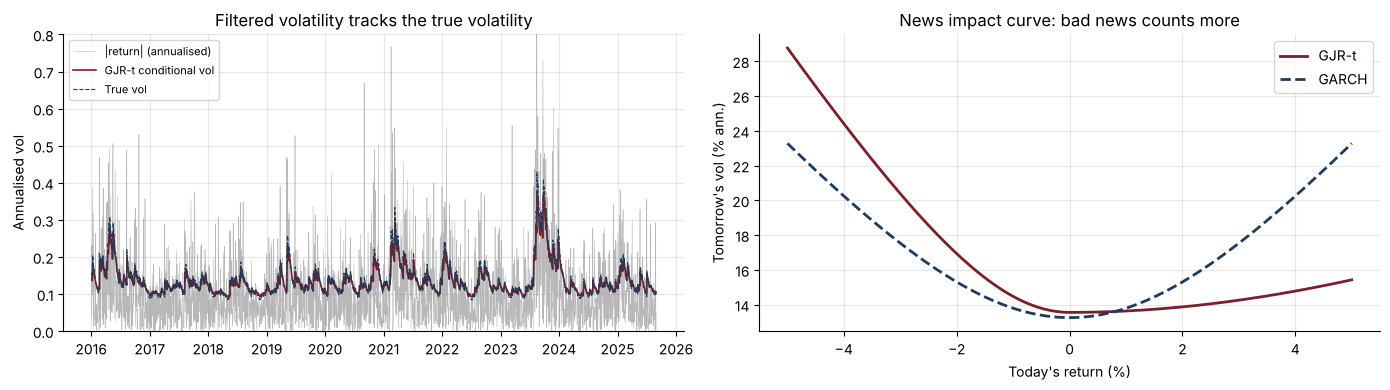

In [4]:
best = fits["GJR (Student-t)"]
shocks = np.linspace(-0.05, 0.05, 201)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cond_vol = np.sqrt(variance_path(r - best.mu, best.omega, best.alpha, best.gamma, best.beta)[:-1] * 252)
axes[0].plot(dates, np.abs(r) * np.sqrt(252), color=GREY, lw=0.4, alpha=0.6, label="|return| (annualised)")
axes[0].plot(dates, cond_vol, color=BORDEAUX, lw=1.2, label="GJR-t conditional vol")
axes[0].plot(dates, np.sqrt(true_var * 252), color=NAVY, lw=0.8, ls="--", label="True vol")
axes[0].set(ylim=(0, 0.8), ylabel="Annualised vol", title="Filtered volatility tracks the true volatility"); axes[0].legend(fontsize=8)
axes[1].plot(shocks * 100, np.sqrt(news_impact(best, shocks) * 252) * 100, color=BORDEAUX, lw=2, label="GJR-t")
axes[1].plot(shocks * 100, np.sqrt(news_impact(fits["GARCH (normal)"], shocks) * 252) * 100, color=NAVY, lw=2, ls="--", label="GARCH")
axes[1].set(xlabel="Today's return (%)", ylabel="Tomorrow's vol (% ann.)", title="News impact curve: bad news counts more"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/conditional_vol.png", dpi=150); plt.show()

## 3. Out-of-sample forecasting contest

Each model forecasts tomorrow's variance using data up to today (GARCH parameters stay
fixed at their in-sample estimates). Forecasts are scored two ways:

- **QLIKE** against squared returns, the only scoring that works with real data;
- **error against the true variance**, available here because the data are simulated.

In [5]:
oos = slice(split, n)
forecasts = {}
s = pd.Series(r)
forecasts["Historical 20d"] = (s**2).rolling(20).mean().shift(1).values
forecasts["Historical 60d"] = (s**2).rolling(60).mean().shift(1).values
forecasts["EWMA 0.94"] = ewma_variance(r)[:-1]
for name, f in fits.items():
    forecasts[name] = variance_path(r - f.mu, f.omega, f.alpha, f.gamma, f.beta)[:-1]
rows = []
for name, fc in forecasts.items():
    fc_oos = fc[oos]
    rows.append({"Model": name, "QLIKE vs r²": qlike(r[oos] ** 2 + 1e-12, fc_oos),
                 "RMSE vs true vol (ann. pts)": np.sqrt(np.mean((np.sqrt(fc_oos * 252) - np.sqrt(true_var[oos] * 252)) ** 2)) * 100})
contest = pd.DataFrame(rows).set_index("Model").sort_values("RMSE vs true vol (ann. pts)")
contest.round(3)

,QLIKE vs r²,RMSE vs true vol (ann. pts)
Model,,
GJR (Student-t),1.443,1.038
GJR (normal),1.443,1.088
GARCH (normal),1.480,2.104
EWMA 0.94,1.529,2.105
Historical 20d,1.616,2.681
Historical 60d,1.568,3.907


## 4. Forecasting the volatility term structure

GARCH forecasts revert to the long-run level at a speed set by the persistence: after a
shock, tomorrow's vol is high, but the average vol over the next three months is much
lower. This is the shape of the implied-volatility term structure after a sell-off.

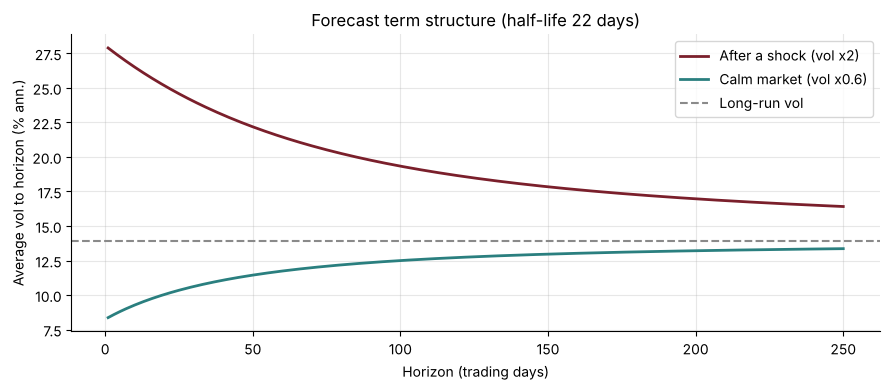

In [6]:
lr_var = best.long_run_vol**2
horizon = 250
plt.figure(figsize=(9, 4))
for start, label, c in [(4 * lr_var, "After a shock (vol x2)", BORDEAUX), (0.36 * lr_var, "Calm market (vol x0.6)", TEAL)]:
    path = forecast_variance(best, start, horizon)
    avg_vol = np.sqrt(np.cumsum(path) / np.arange(1, horizon + 1) * 252)
    plt.plot(np.arange(1, horizon + 1), avg_vol * 100, color=c, lw=2, label=label)
plt.axhline(np.sqrt(lr_var * 252) * 100, color=GREY, ls="--", label="Long-run vol")
plt.xlabel("Horizon (trading days)"); plt.ylabel("Average vol to horizon (% ann.)"); plt.legend()
plt.title(f"Forecast term structure (half-life {best.half_life:.0f} days)")
plt.tight_layout(); plt.savefig("images/term_structure.png", dpi=150); plt.show()

## 5. Application: 99% VaR

In [7]:
q_t = student_t.ppf(0.01, best.nu) * np.sqrt((best.nu - 2) / best.nu)
var_models = {"EWMA + normal": -norm.ppf(0.01) * np.sqrt(forecasts["EWMA 0.94"][oos]),
              "GJR + normal quantile": -norm.ppf(0.01) * np.sqrt(forecasts["GJR (Student-t)"][oos]),
              "GJR + Student-t quantile": -q_t * np.sqrt(forecasts["GJR (Student-t)"][oos])}
T = n - split
pd.DataFrame({k: {"Exceptions": int((r[oos] < -v).sum()), "Expected": round(0.01 * T, 1), "Rate": (r[oos] < -v).mean()}
              for k, v in var_models.items()}).T

,Exceptions,Expected,Rate
EWMA + normal,14.0,7.6,0.018519
GJR + normal quantile,11.0,7.6,0.014550
GJR + Student-t quantile,8.0,7.6,0.010582


## Conclusions
- Maximum likelihood lands close to the true parameters; GJR-t is preferred by AIC and
  captures both the leverage effect and the fat tails.
- Out of sample, GJR forecasts halve the error of EWMA and rolling windows against the
  true volatility (about 1 vol point against 2 to 4). QLIKE against squared returns, the
  only score available on real data, gives the same ranking.
- With a Student-t quantile, the GARCH VaR gives an exception rate close to 1%.
- **Next steps:** realised volatility from intraday data (HAR model), multivariate DCC-GARCH
  for correlations, and GARCH option pricing (Heston-Nandi).